In [1]:
import pandas as pd
import re, sys, os, glob, shutil
import numpy as np
from tqdm import tqdm
from typing import List, Dict, Any, Optional
sys.path.insert(0, '..')
from edautils.qchem import mk_qchem_eda_input
from edautils.qchem import parse_qchem_eda_output

pication_dir = os.getcwd()

# Convert Frag to XYZ

In [2]:
def row2xyz(row, xyz, comment):
    """
    Convert row of Dataframe to XYZ file
    
    Parameters
    ----------
    row: pd.Series object
        Must have a column called 'xyz' containing 3D coordinates
        and a column 'elements' containing atom symbols
    xyz: os.PathLike
        The path to the written XYZ file
    comment: Any
        The comment line in the xyz file
    """
    
    fp = open(xyz, 'w')
    xyz = row['xyz'].split()
    elements = row['elements'].split()
    fp.write(f'{len(elements)}\n{comment}\n')
    for i in range(len(elements)):
        fp.write(f"{elements[i]} {xyz[i*3]} {xyz[i*3+1]} {xyz[i*3+2]}\n")        
    fp.close()

In [3]:
eda_dir = os.path.join(pication_dir, 'pi_cation_EDA')
os.chdir(pication_dir)

In [4]:
df = pd.read_csv('pi_cation.csv')
print(len(df.index))

if not os.path.isdir(eda_dir):
    os.mkdir(eda_dir)
    
os.chdir(eda_dir)

for index, row in df.iterrows():
    interaction = os.path.join(eda_dir, row[0])
    
    if not os.path.isdir(interaction):
        os.mkdir(interaction)

    xyzdir = os.path.join(interaction, 'struct.xyz')
    row2xyz(row, xyzdir, index)

1531


# Generate Input

In [5]:
def generate_fragments(row):
    natoms0 = int(row['natoms0'])
    natoms1 = int(row['natoms1'])
    elements = row['elements'].split()
    xyz = row['xyz'].split()
    xyz = list(map(float, xyz))
    xyz = [xyz[coord * 3:(coord + 1) * 3] for coord in range(len(elements))]
    atoms = [elements[:natoms0], elements[-natoms1:]]
    coords = [xyz[:natoms0], xyz[-natoms1:]]
    charges = [int(row['charge0']), int(row['charge1'])]
    return atoms, coords, charges

In [6]:
names = ['fragment1', 'fragment2']

for interaction in glob.glob('*'):
    edain = os.path.join(interaction, 'eda.in')
    xyz = os.path.join(interaction, 'struct.xyz')
    fp = open(xyz, 'r')
    for i, line in enumerate(fp):
        if i == 1:
            index = int(line)
    fp.close()
    atoms, coords, charges = generate_fragments(df.iloc[index])
    mk_qchem_eda_input(atoms, coords, charges, names, edain)

# Parse Output + Data Group

In [43]:
os.chdir(pication_dir)
df = pd.read_csv('pi_cation_pre-EDA.csv', index_col=0)
df.shape

(1531, 29)

In [44]:
dfEDA = pd.DataFrame()

errs = []

for interaction in tqdm(glob.glob('pi_cation_EDA/*/')):
    out = os.path.join(interaction, 'eda.out')
    try: 
        index = os.path.basename(os.path.normpath(interaction))
        series = df.loc[index]
        seriesEDA = pd.Series(parse_qchem_eda_output(out))
        seriesEDA = pd.concat([series, seriesEDA])
        seriesEDA.name = index
        dfEDA = pd.concat([dfEDA, seriesEDA.to_frame().T])
    except Exception as e:
        errs.append((e, index))

print(len(errs))
print(errs)

dfEDA.rename(columns={'Unnamed: 0': ''}, inplace=True)
# dfEDA.to_csv('pi_cation_EDA.csv')
dfEDA


  0%|          | 0/1531 [00:00<?, ?it/s]

100%|██████████| 1531/1531 [00:01<00:00, 960.31it/s]

0
[]


,PDBID,full_PDBID,subdir,resnr,restype,reschain,prot_idx_list,resnr_lig,restype_lig,reschain_lig,...,PAULI,DISP,CLS_ELEC,MOD_PAULI,CLS_DISP,PREPARATION,FROZEN,POLARIZATION,CHARGE_TRANSFER,TOTAL
5u5h_290_ARG_4655-4661_1-15,5u5h,5u5h_7VV_A_501,pdbbind_opt_sm/,290,ARG,A,4655 4658 4661,1,UNL,Z,...,53.2513,-32.1431,-22.7809,32.0664,NaN,0.0,-22.8576,-14.6666,-3.1013,-40.6255
4bgk_178_TYR_2923-2932_7,4bgk,4bgk_RTK_A_401,pdbbind_opt_sm/,178,TYR,A,2923 2924 2926 2928 2930 2932,1,UNL,Z,...,26.1869,-18.0813,-21.6965,16.5566,NaN,0.0,-23.2212,-12.3659,-3.2441,-38.8312
2v3e_316_TYR_4955-4964_9,2v3e,2v3e_NND_A_1502,pdbbind_opt_sm/,316,TYR,A,4955 4956 4958 4960 4962 4964,1,UNL,Z,...,31.1418,-20.6161,-11.3682,19.74,NaN,0.0,-12.2443,-14.6518,-3.8239,-30.72
2yi6_44_LYS_731_6-11,2yi6,2yi6_6QM_A_1225,biolip2_opt/,44,LYS,A,731,1,UNL,Z,...,6.6868,-7.846,-3.2649,4.2428,NaN,0.0,-6.8682,-25.1862,-1.8892,-33.9436
3l6h_166_TRP_2510-2523_1,3l6h,3l6h_BET_A_1,pdbbind_opt_sm/,166,TRP,A,2510 2511 2513 2514 2516 2517 2519 2521 2523,1,UNL,Z,...,50.4622,-29.4068,-36.6175,33.0885,NaN,0.0,-32.9359,-19.2444,-6.3103,-58.4906
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4hy1_66_ARG_1051-1057_2-10,4hy1,4hy1_19X_A_1401,pdbbind_opt_sm/,66,ARG,A,1051 1054 1057,1,UNL,Z,...,20.3323,-22.3283,-11.2687,10.2693,NaN,0.0,-23.3277,-12.4901,-1.7422,-37.56
6u9k_72_TYR_1243-1252_44,6u9k,6u9k_Q2V_A_4002,biolip2_opt/,72,TYR,A,1243 1244 1246 1248 1250 1252,1,UNL,Z,...,43.6909,-23.9023,-26.5447,28.0664,NaN,-0.0,-22.3806,-13.4606,-4.9922,-40.8334
5emj_316_PHE_5147-5156_10,5emj,5emj_5QJ_A_702,pdbbind_opt_sm/,316,PHE,A,5147 5148 5150 5152 5154 5156,1,UNL,Z,...,34.5243,-19.7352,-24.219,22.5673,NaN,0.0,-21.3869,-13.3908,-4.1138,-38.8915
4qfs_368_ARG_6044-6050_5-16,4qfs,4qfs_32H_A_602,pdbbind_opt_sm/,368,ARG,B,6044 6047 6050,1,UNL,Z,...,34.0953,-24.6137,13.4426,19.8926,NaN,0.0,8.7215,-18.7803,-3.1427,-13.2015


# PLIP Ring Aromaticity Validation

In [45]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')
from edautils.fragment import find_rings_old


processed_df = dfEDA.copy()

df_aromatic_lig = processed_df.query("protcharged == True")
df_aromatic_prot = processed_df.query("protcharged == False")

hetrocyclic_prot = []
carbocyclic_prot = []


for index, row in df_aromatic_prot.iterrows():
    if row['restype'] == 'HIS' or row['restype'] == 'TRP':
        hetrocyclic_prot.append(index)
    if row['restype'] == 'TYR' or row['restype'] == 'PHE':
        carbocyclic_prot.append(index)


dataset_dir = '../dataset'

hetrocyclic_lig = []
carbocyclic_lig = []

hetrocyclic_atoms = []
carbocyclic_atoms = []

errs = []

for index, row in df_aromatic_lig.iterrows():
    aromatic = True
    temp_atomlist = []
    ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    ring_list = find_rings_old(mol, find_hetero_rings=False, find_small_rings=False) # only aromatic rings, idx numbers in OpenBabel 1 lower than Plip

    lig_idx_list = row['lig_idx_list'].split()
    lig_idx_set = set([int(id) - 1 for id in lig_idx_list])
    ring_temp = [s for s in ring_list if lig_idx_set & s]
    
    try:
        for idx in ring_temp[0]:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
            if not symbol == 'C':
                aromatic = False

        if aromatic:
            carbocyclic_lig.append(index)
            carbocyclic_atoms.append((index, temp_atomlist)) # keep the list of atoms
        else:
            hetrocyclic_lig.append(index)
            hetrocyclic_atoms.append((index, temp_atomlist)) # keep the list of atoms
    except Exception as e:
        for idx in lig_idx_set:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
        print(index, lig_idx_set, ring_list)
        errs.append(index)

errs

1m74_495_LYS_7847_11-17 {10, 11, 12, 14, 16} [{17, 18, 19, 20, 21, 23, 24, 25, 26}]
1lke_55_ARG_899-905_2-6 {1, 2, 3, 4, 5} []
4oma_210_LYS_3138_17-22 {16, 17, 19, 20, 21} [{0, 1, 3, 5, 7, 8}]
5a3r_175_ARG_2826-2832_18-43 {35, 40, 42, 17, 23, 30} [{0, 1, 2, 3, 4, 5, 7, 8, 9}]
4hco_169_LYS_2721_1-6 {0, 1, 2, 3, 4, 5} []
2wf0_223_ARG_3539-3545_24-28 {23, 24, 25, 26, 27} [{0, 1, 2, 3, 4, 5, 43, 22, 29, 30}, {17, 18, 19, 20, 21, 13}, {33, 34, 35, 36, 37, 38}]
2wez_223_ARG_3539-3545_24-28 {23, 24, 25, 26, 27} [{0, 1, 2, 3, 4, 5, 22, 29, 30}, {17, 18, 19, 20, 21, 13}, {33, 34, 35, 36, 37, 38}]
4h71_171_LYS_2746_3-8 {2, 3, 4, 5, 6, 7} []
1lnm_55_ARG_897-903_2-6 {1, 2, 3, 4, 5} []
6npf_350_LYS_5199_5-11 {4, 5, 6, 8, 10} []
5i59_245_ARG_3935-3941_6-26 {5, 6, 23, 24, 25} [{0, 1, 2, 3, 18, 19}, {9, 10, 11, 12, 13, 14}]


['1m74_495_LYS_7847_11-17',
 '1lke_55_ARG_899-905_2-6',
 '4oma_210_LYS_3138_17-22',
 '5a3r_175_ARG_2826-2832_18-43',
 '4hco_169_LYS_2721_1-6',
 '2wf0_223_ARG_3539-3545_24-28',
 '2wez_223_ARG_3539-3545_24-28',
 '4h71_171_LYS_2746_3-8',
 '1lnm_55_ARG_897-903_2-6',
 '6npf_350_LYS_5199_5-11',
 '5i59_245_ARG_3935-3941_6-26']

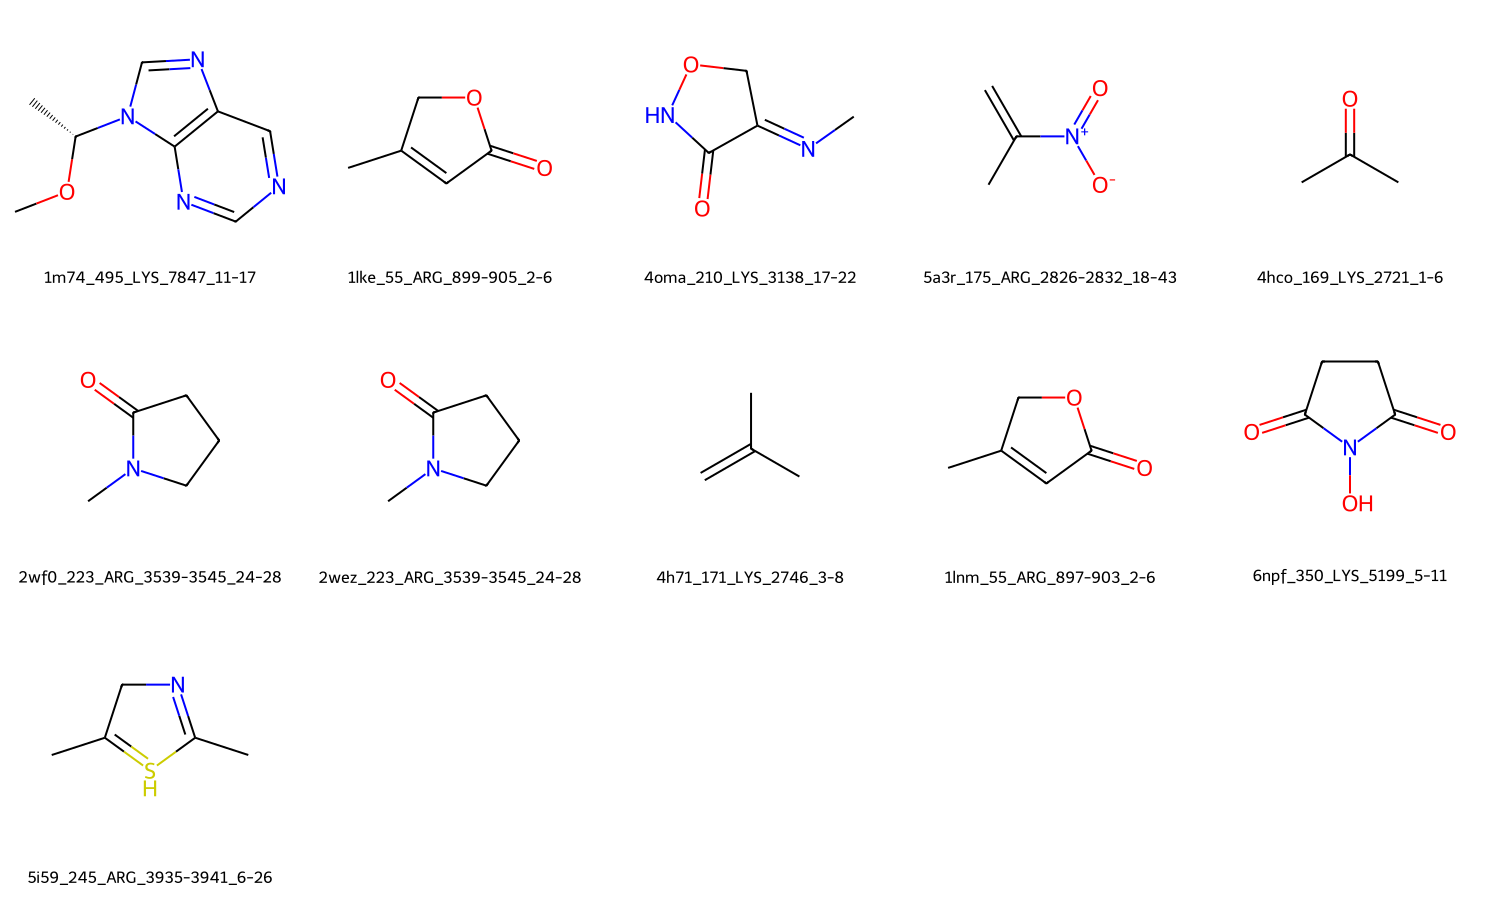

In [ ]:
rows = processed_df.loc[errs, ['smiles0']]
mols = [Chem.MolFromSmiles(s) for s in rows['smiles0']]
legends = [str(idx) for idx in rows.index]

Draw.MolsToGridImage(mols, legends=legends,subImgSize=(300, 300),molsPerRow=5)

['1m74_495_LYS_7847_11-17', # not aromatic, incorrect fragmentation
 '1lke_55_ARG_899-905_2-6', # not aromatic
 '4oma_210_LYS_3138_17-22', # no aromatic
 '5a3r_175_ARG_2826-2832_18-43', # not aromatic, incorrect fragmentation
 '4hco_169_LYS_2721_1-6', # not atomatic
 '2wf0_223_ARG_3539-3545_24-28', # not aromatic
 '2wez_223_ARG_3539-3545_24-28', # not aromatic
 '4h71_171_LYS_2746_3-8', # ? 
 '1lnm_55_ARG_897-903_2-6', # not aromatic
 '6npf_350_LYS_5199_5-11', # not aromatic
 '5i59_245_ARG_3935-3941_6-26'] # not aromatic

In [48]:
processed_df.loc[hetrocyclic_prot, "group"] = "Hetero Prot"
processed_df.loc[hetrocyclic_lig, "group"] = "Hetero Lig"
processed_df.loc[carbocyclic_prot, "group"] = "Carbo Prot"
processed_df.loc[carbocyclic_lig, "group"] = "Carbo Lig"

carbocyclic = carbocyclic_prot + carbocyclic_lig
hetrocyclic = hetrocyclic_prot + hetrocyclic_lig

processed_df.loc[hetrocyclic, "group1"] = "Heterocyclic"
processed_df.loc[carbocyclic, "group1"] = "Carbocyclic"

prot_cat = hetrocyclic_lig + carbocyclic_lig
lig_cat = hetrocyclic_prot + carbocyclic_prot

processed_df.loc[prot_cat, "group2"] = "Cation Prot"
processed_df.loc[lig_cat, "group2"] = "Cation Lig"

for x, subdf in processed_df.groupby("group"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())

print('\n')
for x, subdf in processed_df.groupby("group1"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())

print('\n')
for x, subdf in processed_df.groupby("group2"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())

Carbo Lig 577 -165.7309
Carbo Prot 208 -55.5462
Hetero Lig 526 -153.8949
Hetero Prot 209 -67.2801


Carbocyclic 785 -165.7309
Heterocyclic 735 -153.8949


Cation Lig 417 -67.2801
Cation Prot 1103 -165.7309


In [49]:
processed_df = processed_df.drop(errs)
processed_df.to_csv('pi_cation_EDA.csv')
processed_df.shape

(1520, 43)

# Copy Fragment to EDA directory

In [50]:
errs = []

for index, row in tqdm(dfEDA.iterrows(), total=len(dfEDA)):
    try:
        protfrag = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiCatProteinFragment/{index}.pdb")
        ligfrag = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/PiCatLigandFragment/{index}.sdf")
        edadir = os.path.join(pication_dir, f"pi_cation_EDA/{index}/")

        shutil.copy(protfrag, edadir)
        shutil.copy(ligfrag, edadir)

        if os.path.exists(os.path.join(edadir, f"{index}.pdb")):
            os.rename(os.path.join(edadir, f"{index}.pdb"), os.path.join(edadir, "ProtFragment.pdb"))
        if os.path.exists(os.path.join(edadir, f"{index}.sdf")):
            os.rename(os.path.join(edadir, f"{index}.sdf"), os.path.join(edadir, "LigFragment.sdf"))
    except Exception as e:
        errs.append((index, e))

print(len(errs))
errs

100%|██████████| 1531/1531 [00:02<00:00, 673.41it/s]

0


[]